# 2. CNN + SVC
1. Train a small CNN on cropped characters.
2. Take its 128-d penultimate layer as features, standardise, fit an SVC (kernel and C chosen on the validation set, then calibrated for probabilities).

Uses the shared split from `training/common.py`. `DATA`, `PER_CLASS` and `SEED` must match notebook 03 so both models see the same train/val/test images.

In [1]:
%pip install torchvision

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, sys
from pathlib import Path

# run everything from the project root, whether Jupyter was started there or in notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))  # so `backend.ml.preprocessing` can be imported
print("project root:", ROOT)

project root: D:\Portfolio Projects\MODI Script Identification


In [3]:
# ---- settings ----
DATA = "data/processed/offline_subset"
PER_CLASS = 300
SEED = 42
IMG = 64
EPOCHS = 15
BATCH = 64
LR = 1e-3
CNN_OUT = "models/cnn.pth"
SVC_OUT = "models/svc.joblib"
REPORT_DIR = "reports/cnn_svc"

## Shared split
Same function in notebooks 02 to 05, so every method is trained and tested on the same source images when `DATA`, `PER_CLASS` and `SEED` match.

In [4]:
import cv2
import numpy as np
from sklearn.model_selection import train_test_split

# The crop function lives in the backend because the API must preprocess exactly like training.
from backend.ml.preprocessing import crop_square

EXTS = {".png", ".jpg", ".jpeg", ".bmp"}


def select_and_split(root, per_class=300, seed=42):
    """Returns (classes, paths, labels, {"train": idx, "val": idx, "test": idx}); 70/15/15, stratified.
    Deterministic: the same root, per_class and seed always give the same split."""
    root = Path(root)
    classes = sorted(d.name for d in root.iterdir() if d.is_dir())
    assert classes, f"no class folders found in {root}"
    rng = np.random.RandomState(seed)
    paths, labels = [], []
    for ci, c in enumerate(classes):
        files = sorted(f for f in (root / c).iterdir() if f.suffix.lower() in EXTS)
        if per_class and len(files) > per_class:
            keep = np.sort(rng.choice(len(files), per_class, replace=False))
            files = [files[i] for i in keep]
        paths.extend(files)
        labels.extend([ci] * len(files))
    labels = np.array(labels)
    idx = np.arange(len(paths))
    tr, tmp = train_test_split(idx, test_size=0.3, stratify=labels, random_state=seed)
    va, te = train_test_split(tmp, test_size=0.5, stratify=labels[tmp], random_state=seed)
    return classes, paths, labels, {"train": tr, "val": va, "test": te}


def load_crops(paths, size):
    """(N, size, size) uint8: tight-cropped, padded square, dark ink on white (same as the API)."""
    out = np.full((len(paths), size, size), 255, np.uint8)
    bad = 0
    for i, p in enumerate(paths):
        g = cv2.imread(str(p), cv2.IMREAD_GRAYSCALE)
        if g is None:
            bad += 1
            continue
        out[i] = crop_square(g, size)
    if bad:
        print(f"warning: {bad} unreadable images were left blank")
    return out

In [5]:
import json, random, time

import joblib
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from torchvision import transforms

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
for p in (CNN_OUT, SVC_OUT):
    Path(p).parent.mkdir(parents=True, exist_ok=True)
Path(REPORT_DIR).mkdir(parents=True, exist_ok=True)
print("device:", device)

device: cpu


## Data
Crops are `(N, 1, H, W)` float tensors in [0, 1] (background = 1).

In [6]:
classes, paths, labels, split = select_and_split(DATA, PER_CLASS, SEED)
crops = torch.from_numpy(load_crops(paths, IMG)).float().div(255).unsqueeze(1)
X = {k: crops[split[k]] for k in split}
y = {k: labels[split[k]] for k in split}
print(f"classes={len(classes)} train/val/test={[len(y[k]) for k in split]}")

classes=57 train/val/test=[11970, 2565, 2565]


## Model

In [7]:
class ModiCNN(nn.Module):
    """4 x (Conv -> BatchNorm -> ReLU -> MaxPool), then Dense128 -> Dense(classes).
    Keep in sync with backend/ml/cnn_model.py. IMG must be a multiple of 16."""

    def __init__(self, num_classes, img=64):
        super().__init__()

        def block(i, o):
            return [nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(), nn.MaxPool2d(2)]

        self.features = nn.Sequential(*block(1, 32), *block(32, 64), *block(64, 128), *block(128, 256))
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(256 * (img // 16) ** 2, 128), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(128, num_classes),
        )

    def embed(self, x):
        """128-d features (everything before the last layer); this is the SVC's input."""
        return self.classifier[:-1](self.features(x))

    def forward(self, x):
        return self.classifier(self.features(x))


def norm(x):
    return (x - 0.5) / 0.5  # [0, 1] -> [-1, 1], same as the API


@torch.no_grad()
def apply(fn, X, bs=256):
    """Run fn (the model, or model.embed) over X in batches; returns a numpy array."""
    return torch.cat([fn(norm(X[i:i + bs]).to(device)).cpu() for i in range(0, len(X), bs)]).numpy()


model = ModiCNN(len(classes), IMG).to(device)

## Stage 1: train the CNN

epoch 01 loss=4.5071 val_acc=0.1158
epoch 02 loss=3.2198 val_acc=0.3135
epoch 03 loss=3.0299 val_acc=0.3739
epoch 04 loss=3.2971 val_acc=0.4659
epoch 05 loss=1.5082 val_acc=0.5867
epoch 06 loss=2.0140 val_acc=0.6425
epoch 07 loss=0.6447 val_acc=0.6717
epoch 08 loss=1.6020 val_acc=0.6885
epoch 09 loss=1.1055 val_acc=0.6663
epoch 10 loss=1.8756 val_acc=0.6858
epoch 11 loss=2.9932 val_acc=0.7567
epoch 12 loss=1.5232 val_acc=0.7135
epoch 13 loss=1.8507 val_acc=0.6834
epoch 14 loss=2.3219 val_acc=0.6901
epoch 15 loss=3.5237 val_acc=0.6577
CNN alone: test accuracy=0.7481


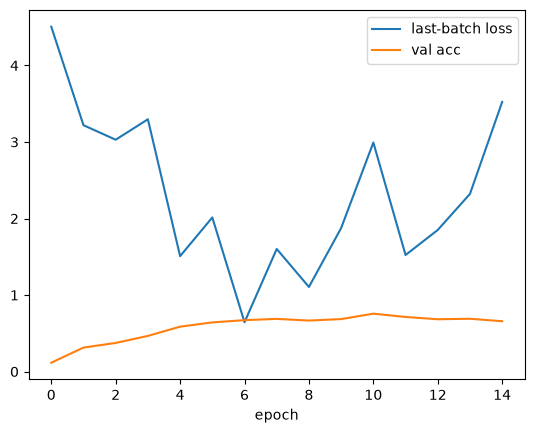

In [8]:
opt = torch.optim.Adam(model.parameters(), lr=LR)
aug = transforms.RandomAffine(4, translate=(0.03, 0.03), scale=(0.95, 1.05), fill=1.0)
ytr = torch.from_numpy(y["train"]).long()
history, best_val = [], 0.0
for epoch in range(1, EPOCHS + 1):
    model.train()
    perm = torch.randperm(len(ytr))
    for i in range(0, len(perm), BATCH):
        idx = perm[i:i + BATCH]
        xb = torch.stack([aug(x) for x in X["train"][idx]])  # random shift / rotate / zoom
        loss = F.cross_entropy(model(norm(xb).to(device)), ytr[idx].to(device))
        opt.zero_grad(); loss.backward(); opt.step()
    model.eval()
    val_acc = (apply(model, X["val"]).argmax(1) == y["val"]).mean()
    history.append((loss.item(), float(val_acc)))
    print(f"epoch {epoch:02d} loss={loss.item():.4f} val_acc={val_acc:.4f}")
    if val_acc > best_val:  # keep the best epoch
        best_val = val_acc
        torch.save({"state_dict": model.state_dict(), "classes": classes, "img": IMG}, CNN_OUT)

model.load_state_dict(torch.load(CNN_OUT, map_location=device)["state_dict"])
model.eval()
cnn_test = (apply(model, X["test"]).argmax(1) == y["test"]).mean()
print(f"CNN alone: test accuracy={cnn_test:.4f}")

plt.plot([h[0] for h in history], label="last-batch loss")
plt.plot([h[1] for h in history], label="val acc")
plt.xlabel("epoch"); plt.legend(); plt.show()

## Stage 2: SVC on the CNN's features
The scaler is fitted on the training set only.

In [9]:
SVC_CANDIDATES = [("linear", 1), ("rbf", 1), ("rbf", 10), ("rbf", 100)]  # (kernel, C)

Z = {k: apply(model.embed, X[k]) for k in split}
scaler = StandardScaler().fit(Z["train"])
S = {k: scaler.transform(Z[k]) for k in split}

scores = {}
for kernel, C in SVC_CANDIDATES:
    svc = SVC(kernel=kernel, C=C).fit(S["train"], y["train"])
    scores[(kernel, C)] = (svc.score(S["train"], y["train"]), svc.score(S["val"], y["val"]))
    print(f"SVC {kernel:6s} C={C:<4} train={scores[(kernel, C)][0]:.4f} val={scores[(kernel, C)][1]:.4f}")
kernel, C = max(scores, key=lambda k: scores[k][1])  # best on validation

# sigmoid calibration gives predict_proba for the API
calibrated = CalibratedClassifierCV(SVC(kernel=kernel, C=C), method="sigmoid", cv=3,
                                    ensemble=False).fit(S["train"], y["train"])
pipe = Pipeline([("scale", scaler), ("svc", calibrated)])
preds = pipe.predict(Z["test"])
svc_test = (preds == y["test"]).mean()

with torch.no_grad():  # time the whole CNN -> SVC chain on one image
    x1 = norm(X["test"][:1]).to(device)
    t = time.perf_counter()
    for _ in range(50):
        pipe.predict_proba(model.embed(x1).cpu().numpy())
    ms = (time.perf_counter() - t) / 50 * 1000
print(f"CNN + SVC ({kernel}, C={C}): test accuracy={svc_test:.4f} | {ms:.1f} ms/image")
joblib.dump({"pipeline": pipe, "classes": classes, "img": IMG, "name": "cnn_svc"}, SVC_OUT)

SVC linear C=1    train=0.8399 val=0.7871
SVC rbf    C=1    train=0.8359 val=0.7848
SVC rbf    C=10   train=0.8656 val=0.7918
SVC rbf    C=100  train=0.9037 val=0.7758
CNN + SVC (rbf, C=10): test accuracy=0.7856 | 209.0 ms/image


['models/svc.joblib']

## Report

              precision    recall  f1-score   support

           a      0.889     0.889     0.889        45
          aa      0.804     0.822     0.813        45
          ah      0.875     0.933     0.903        45
          ai      0.860     0.822     0.841        45
          am      0.851     0.889     0.870        45
           b      0.750     0.800     0.774        45
          bh      0.534     0.689     0.602        45
          ch      0.953     0.911     0.932        45
         chh      0.900     0.800     0.847        45
           d      0.708     0.756     0.731        45
          dh      0.975     0.867     0.918        45
         dha      0.604     0.644     0.624        45
         dyn      0.925     0.822     0.871        45
           e      0.848     0.867     0.857        45
       eight      0.952     0.889     0.920        45
        five      0.902     0.822     0.860        45
        four      0.891     0.911     0.901        45
           g      0.971    

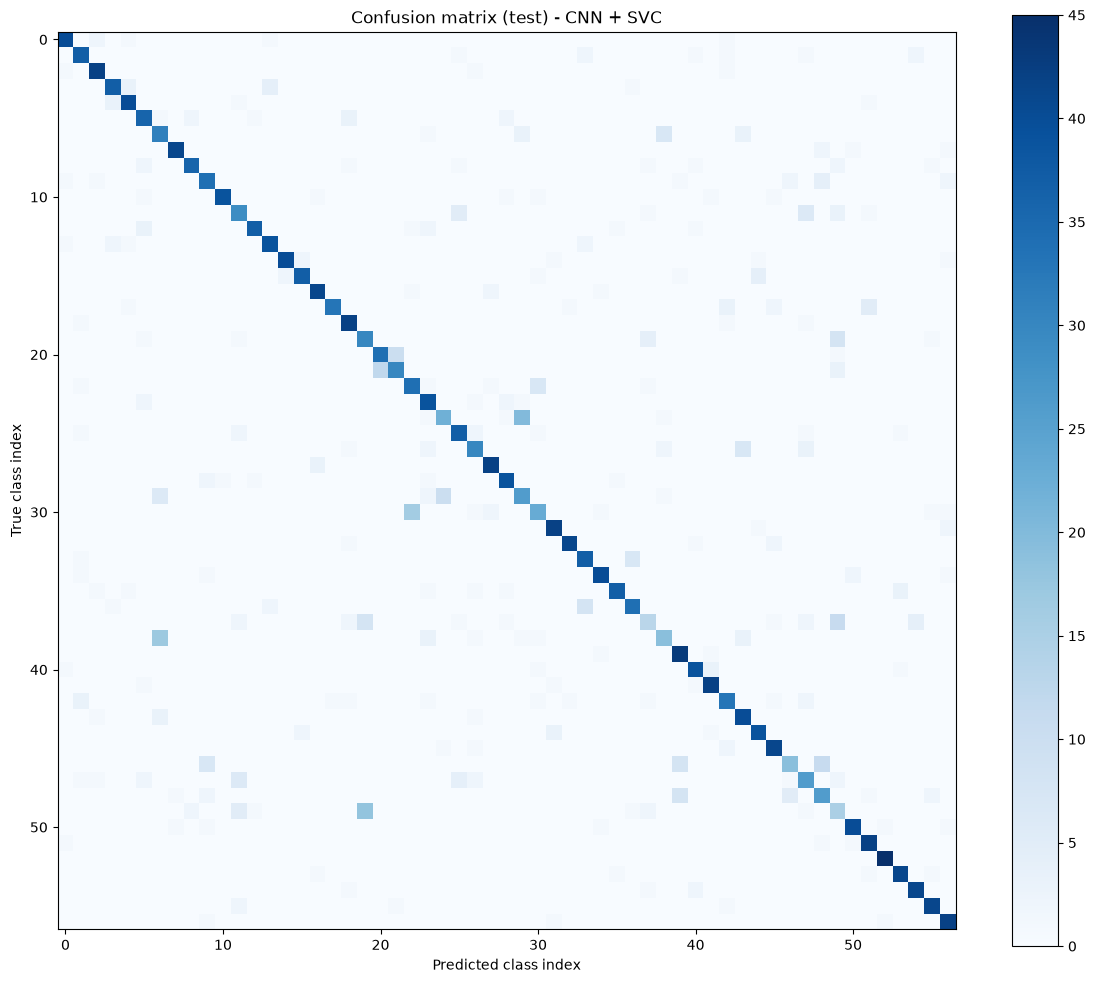

saved models/cnn.pth, models/svc.joblib and reports in reports/cnn_svc/


In [10]:
names = list(range(len(classes)))
text = classification_report(y["test"], preds, labels=names, target_names=classes,
                             digits=3, zero_division=0)
(Path(REPORT_DIR) / "classification_report.txt").write_text(text)
print(text)

plt.figure(figsize=(12, 10))
plt.imshow(confusion_matrix(y["test"], preds, labels=names), cmap="Blues")
plt.colorbar()
plt.title("Confusion matrix (test) - CNN + SVC")
plt.xlabel("Predicted class index"); plt.ylabel("True class index")
plt.tight_layout()
plt.savefig(Path(REPORT_DIR) / "confusion_matrix.png", dpi=150)
plt.show()

(Path(REPORT_DIR) / "metrics.json").write_text(json.dumps({
    "cnn_test_accuracy": float(cnn_test),
    "cnn_svc_test_accuracy": float(svc_test),
    "svc_best": {"kernel": kernel, "C": C},
    "svc_candidates": [{"kernel": k, "C": c, "train_acc": float(a), "val_acc": float(v)}
                       for (k, c), (a, v) in scores.items()],
    "inference_ms_per_image": ms,
    "num_classes": len(classes),
}, indent=2))
print(f"saved {CNN_OUT}, {SVC_OUT} and reports in {REPORT_DIR}/")